In [27]:
import numpy as np
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
from sklearn.metrics import roc_curve
from sklearn.preprocessing import MinMaxScaler
from sklearn.preprocessing import StandardScaler
from sklearn.model_selection import train_test_split, StratifiedKFold, cross_val_score
from sklearn.ensemble import RandomForestClassifier, GradientBoostingClassifier
from sklearn.metrics import classification_report, roc_auc_score, confusion_matrix

In [4]:
df = pd.read_csv('/content/matches_all_20260515_211601.csv')
df.head()

,id,match_type,compatibility_score,viewed,saved,action_taken,feedback_type,label_relevant,label_not_relevant,user_identity_verified,...,skills_count_a,skills_count_b,complementarity,unique_skills_a,unique_skills_b,user_a_verified,user_b_verified,both_identity_verified,overlapping_skills_count,covered_skills_count
0,476436f4-2e0f-4870-aee1-a3398a083d1e,collaborator,0.42,1,0,1,NaN,0,0,0,...,5,8,0.917,5.0,8.0,0.0,1.0,0.0,1.0,0.0
1,4c458065-b71c-42fd-84a6-2ff939b604ae,collaborator,0.42,1,0,1,relevant,1,0,0,...,8,7,0.750,8.0,7.0,0.0,1.0,0.0,3.0,0.0
2,6486fc41-f837-44b2-b79a-b19789ca86c6,collaborator,0.41,1,0,0,NaN,0,0,1,...,5,4,1.000,5.0,4.0,1.0,0.0,0.0,0.0,0.0
3,f06e6adb-20d7-4f4a-b3e0-09e6c2b37afa,collaborator,0.42,1,0,1,not_interested,0,0,0,...,6,7,0.917,6.0,7.0,0.0,1.0,0.0,1.0,0.0
4,fc517535-197a-4ddc-916b-55be42ef274c,collaborator,0.55,0,0,0,NaN,0,0,1,...,5,6,0.778,5.0,6.0,1.0,1.0,1.0,2.0,0.0


In [5]:
df.describe()

,compatibility_score,viewed,saved,action_taken,label_relevant,label_not_relevant,user_identity_verified,same_location,project_accepting,team_openness,skills_count_b,complementarity,unique_skills_a,unique_skills_b,user_a_verified,user_b_verified,both_identity_verified,overlapping_skills_count,covered_skills_count
count,1288.000000,1288.000000,1288.000000,1288.000000,1288.000000,1288.000000,1288.000000,1288.000000,1288.000000,1288.000000,1288.000000,1258.000000,1199.000000,800.000000,800.000000,800.000000,800.000000,800.000000,800.0
mean,0.491599,0.659161,0.201863,0.675466,0.121894,0.256211,0.609472,0.058230,0.166149,0.250106,4.382764,0.573742,4.035863,5.525000,0.596250,0.587500,0.346250,0.972500,0.0
std,0.130607,0.474175,0.401547,0.468382,0.327291,0.436709,0.488058,0.234268,0.372359,0.361534,2.218152,0.441229,2.736243,1.791197,0.490955,0.492592,0.476072,0.922121,0.0
min,0.300000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,3.000000,0.000000,0.000000,0.000000,0.000000,0.0
25%,0.410000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,3.000000,0.000000,1.000000,4.000000,0.000000,0.000000,0.000000,0.000000,0.0
50%,0.435000,1.000000,0.000000,1.000000,0.000000,0.000000,1.000000,0.000000,0.000000,0.000000,4.000000,0.833000,4.000000,6.000000,1.000000,1.000000,0.000000,1.000000,0.0
75%,0.560000,1.000000,0.000000,1.000000,0.000000,1.000000,1.000000,0.000000,0.000000,0.667000,6.000000,0.923000,7.000000,7.000000,1.000000,1.000000,1.000000,2.000000,0.0
max,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,0.960000,8.000000,1.000000,8.000000,8.000000,1.000000,1.000000,1.000000,5.000000,0.0


In [6]:
df.isna().sum()

,0
id,0
match_type,69
compatibility_score,0
viewed,0
saved,0
action_taken,0
feedback_type,572
label_relevant,0
label_not_relevant,0
user_identity_verified,0


In [7]:
print('Columns:', list(df.columns))

Columns: ['id', 'match_type', 'compatibility_score', 'viewed', 'saved', 'action_taken', 'feedback_type', 'label_relevant', 'label_not_relevant', 'user_identity_verified', 'same_location', 'project_accepting', 'team_openness', 'skill_overlap', 'location_match', 'skills_count_a', 'skills_count_b', 'complementarity', 'unique_skills_a', 'unique_skills_b', 'user_a_verified', 'user_b_verified', 'both_identity_verified', 'overlapping_skills_count', 'covered_skills_count']


# Data Cleaning & Preprocessing

In [8]:
# Step 2: Data Cleaning & Preprocessing

df_clean = df.copy()

drop_cols = [
    'id',
    'feedback_type',
    'label_not_relevant'  # perfectly inverse of label_relevant → data leakage
]
df_clean.drop(columns=drop_cols, inplace=True)

# Encode categorical column
df_clean['match_type'] = df_clean['match_type'].fillna('unknown')
df_clean['match_type'] = df_clean['match_type'].map(
    {'collaborator': 0, 'project': 1, 'unknown': -1}
)
print('Encoded match_type:', df_clean['match_type'].value_counts().to_dict())

# Fill missing numeric values with column median
# Ensure columns are numeric before calculating median
for col in ['skill_overlap', 'skills_count_a', 'complementarity', 'unique_skills_a', 'unique_skills_b', 'user_a_verified', 'user_b_verified', 'both_identity_verified', 'overlapping_skills_count', 'covered_skills_count']:
    if col in df_clean.columns:
        df_clean[col] = pd.to_numeric(df_clean[col], errors='coerce')


Encoded match_type: {0: 815, 1: 404, -1: 69}


In [9]:
num_cols_with_na = df_clean.columns[df_clean.isnull().any()].tolist()
print(f'Columns with NaN before fill: {num_cols_with_na}')

for col in num_cols_with_na:
      median_val = df_clean[col].median()
      df_clean[col].fillna(median_val, inplace=True)

print(f'NaN after fill: {df_clean.isnull().sum()}')

Columns with NaN before fill: ['skill_overlap', 'skills_count_a', 'complementarity', 'unique_skills_a', 'unique_skills_b', 'user_a_verified', 'user_b_verified', 'both_identity_verified', 'overlapping_skills_count', 'covered_skills_count']
NaN after fill: match_type                  0
compatibility_score         0
viewed                      0
saved                       0
action_taken                0
label_relevant              0
user_identity_verified      0
same_location               0
project_accepting           0
team_openness               0
skill_overlap               0
location_match              0
skills_count_a              0
skills_count_b              0
complementarity             0
unique_skills_a             0
unique_skills_b             0
user_a_verified             0
user_b_verified             0
both_identity_verified      0
overlapping_skills_count    0
covered_skills_count        0
dtype: int64


/tmp/ipykernel_8636/3018679459.py:6: FutureWarning: A value is trying to be set on a copy of a DataFrame or Series through chained assignment using an inplace method.
The behavior will change in pandas 3.0. This inplace method will never work because the intermediate object on which we are setting values always behaves as a copy.

For example, when doing 'df[col].method(value, inplace=True)', try using 'df.method({col: value}, inplace=True)' or df[col] = df[col].method(value) instead, to perform the operation inplace on the original object.


  df_clean[col].fillna(median_val, inplace=True)


In [10]:
print(f'Clean shape: {df_clean.shape}')
df_clean.head()

Clean shape: (1288, 22)


,match_type,compatibility_score,viewed,saved,action_taken,label_relevant,user_identity_verified,same_location,project_accepting,team_openness,...,skills_count_a,skills_count_b,complementarity,unique_skills_a,unique_skills_b,user_a_verified,user_b_verified,both_identity_verified,overlapping_skills_count,covered_skills_count
0,0,0.42,1,0,1,0,0,0,0,0.0,...,5.0,8,0.917,5.0,8.0,0.0,1.0,0.0,1.0,0.0
1,0,0.42,1,0,1,1,0,0,0,0.0,...,8.0,7,0.750,8.0,7.0,0.0,1.0,0.0,3.0,0.0
2,0,0.41,1,0,0,0,1,0,0,0.0,...,5.0,4,1.000,5.0,4.0,1.0,0.0,0.0,0.0,0.0
3,0,0.42,1,0,1,0,0,0,0,0.0,...,6.0,7,0.917,6.0,7.0,0.0,1.0,0.0,1.0,0.0
4,0,0.55,0,0,0,0,1,0,0,0.0,...,5.0,6,0.778,5.0,6.0,1.0,1.0,1.0,2.0,0.0


# Feature Engineering


In [11]:
df_feat = df_clean.copy()

df_feat['total_skills'] = df_feat['skills_count_a'] + df_feat['skills_count_b']
df_feat['overlap_ratio'] = np.where(
    df_feat['total_skills'] > 0,
    df_feat['overlapping_skills_count'] / df_feat['total_skills'],
    0
)

In [12]:
# هل الطرفان verified؟
df_feat['trust_score'] = df_feat['user_a_verified'].fillna(0) + df_feat['user_b_verified'].fillna(0)

# نسبة التكامل بين المهارات
df_feat['skill_gap'] = abs(df_feat['skills_count_a'] - df_feat['skills_count_b'])


In [13]:
# Composite readiness
# يجمع project_accepting + team_openness كمؤشر جاهزية للتعاون
df_feat['readiness'] = df_feat['project_accepting'] + df_feat['team_openness']


In [14]:
# Location × identity signal
df_feat['local_verified'] = df_feat['same_location'] * df_feat['user_identity_verified']


In [15]:
print('✅ New features added:')
new_feats = ['total_skills', 'overlap_ratio',  'trust_score',
             'skill_gap', 'readiness', 'local_verified']
print(df_feat[new_feats].describe().round(2))
print(f'Final feature count: {df_feat.shape[1]} columns')

✅ New features added:
       total_skills  overlap_ratio  trust_score  skill_gap  readiness  \
count       1288.00        1288.00      1288.00    1288.00    1288.00   
mean           9.82           0.12         1.49       2.26       0.42   
std            3.28           0.15         0.67       1.71       0.65   
min            0.00           0.00         0.00       0.00       0.00   
25%            8.00           0.06         1.00       1.00       0.00   
50%           10.00           0.10         2.00       2.00       0.00   
75%           12.00           0.14         2.00       3.00       0.80   
max           16.00           1.00         2.00       6.00       1.96   

       local_verified  
count         1288.00  
mean             0.03  
std              0.18  
min              0.00  
25%              0.00  
50%              0.00  
75%              0.00  
max              1.00  
Final feature count: 28 columns


# Train Model

In [16]:
df_feat

,match_type,compatibility_score,viewed,saved,action_taken,label_relevant,user_identity_verified,same_location,project_accepting,team_openness,...,user_b_verified,both_identity_verified,overlapping_skills_count,covered_skills_count,total_skills,overlap_ratio,trust_score,skill_gap,readiness,local_verified
0,0,0.42,1,0,1,0,0,0,0,0.000,...,1.0,0.0,1.0,0.0,13.0,0.076923,1.0,3.0,0.000,0
1,0,0.42,1,0,1,1,0,0,0,0.000,...,1.0,0.0,3.0,0.0,15.0,0.200000,1.0,1.0,0.000,0
2,0,0.41,1,0,0,0,1,0,0,0.000,...,0.0,0.0,0.0,0.0,9.0,0.000000,1.0,1.0,0.000,0
3,0,0.42,1,0,1,0,0,0,0,0.000,...,1.0,0.0,1.0,0.0,13.0,0.076923,1.0,1.0,0.000,0
4,0,0.55,0,0,0,0,1,0,0,0.000,...,1.0,1.0,2.0,0.0,11.0,0.181818,2.0,1.0,0.000,0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
1283,1,0.87,1,1,1,0,0,0,0,0.800,...,1.0,0.0,1.0,0.0,6.0,0.166667,2.0,6.0,0.800,0
1284,1,0.88,1,1,1,0,0,0,0,0.750,...,1.0,0.0,1.0,0.0,6.0,0.166667,2.0,6.0,0.750,0
1285,1,0.72,0,0,0,0,0,0,0,0.875,...,1.0,0.0,1.0,0.0,6.0,0.166667,2.0,6.0,0.875,0
1286,1,0.96,1,1,0,0,1,1,1,0.900,...,1.0,0.0,1.0,0.0,13.0,0.076923,2.0,3.0,1.900,1


In [17]:
target ='label_relevant'
x=df_feat.drop(columns= [target])
y=df_feat[target]
x_train,x_test,y_train,y_test=train_test_split(x,y,test_size=0.2,random_state=42)
print (f"train shape: {x_train.shape}")
print (f"test shape: {x_test.shape}")

train shape: (1030, 27)
test shape: (258, 27)


In [18]:
# Identify and convert any remaining object columns to numeric
for col in x_train.select_dtypes(include='object').columns:
    print(f"Converting column '{col}' to numeric (coercing errors)...")
    x_train[col] = pd.to_numeric(x_train[col], errors='coerce')
    x_test[col] = pd.to_numeric(x_test[col], errors='coerce')

# Fill any NaNs that resulted from coercion (using median from x_train)
for col in x_train.columns:
    if x_train[col].isnull().any():
        median_val = x_train[col].median()
        x_train[col].fillna(median_val, inplace=True)
        x_test[col].fillna(median_val, inplace=True)

Converting column 'location_match' to numeric (coercing errors)...


/tmp/ipykernel_8636/3699262361.py:11: FutureWarning: A value is trying to be set on a copy of a DataFrame or Series through chained assignment using an inplace method.
The behavior will change in pandas 3.0. This inplace method will never work because the intermediate object on which we are setting values always behaves as a copy.

For example, when doing 'df[col].method(value, inplace=True)', try using 'df.method({col: value}, inplace=True)' or df[col] = df[col].method(value) instead, to perform the operation inplace on the original object.


  x_train[col].fillna(median_val, inplace=True)
/tmp/ipykernel_8636/3699262361.py:12: FutureWarning: A value is trying to be set on a copy of a DataFrame or Series through chained assignment using an inplace method.
The behavior will change in pandas 3.0. This inplace method will never work because the intermediate object on which we are setting values always behaves as a copy.

For example, when doing 'df[col].method(value, inplace=True)', try u

In [19]:
scaler = MinMaxScaler()
x_train_sc = scaler.fit_transform(x_train)
x_test_sc = scaler.transform(x_test)

In [20]:
# Train Random Forest (handles imbalance with class_weight)
rf = RandomForestClassifier(
    n_estimators=300,
    max_depth=8,
    class_weight='balanced',  # مهم بسبب الـ imbalance (87% / 13%)
    random_state=42,
    n_jobs=-1
)
rf.fit(x_train_sc, y_train)

RandomForestClassifier(class_weight='balanced', max_depth=8, n_estimators=300,
                       n_jobs=-1, random_state=42)

In [21]:
# Cross-validation
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)
cv_auc = cross_val_score(rf, x_train_sc, y_train, cv=cv, scoring='roc_auc')
print(f'\n5-Fold CV ROC-AUC: {cv_auc.mean():.4f} ± {cv_auc.std():.4f}')



5-Fold CV ROC-AUC: 0.6956 ± 0.0289


/tmp/ipykernel_8636/1314553318.py:4: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x=feat_imp.values[:25], y=feat_imp.index[:25], palette='viridis')


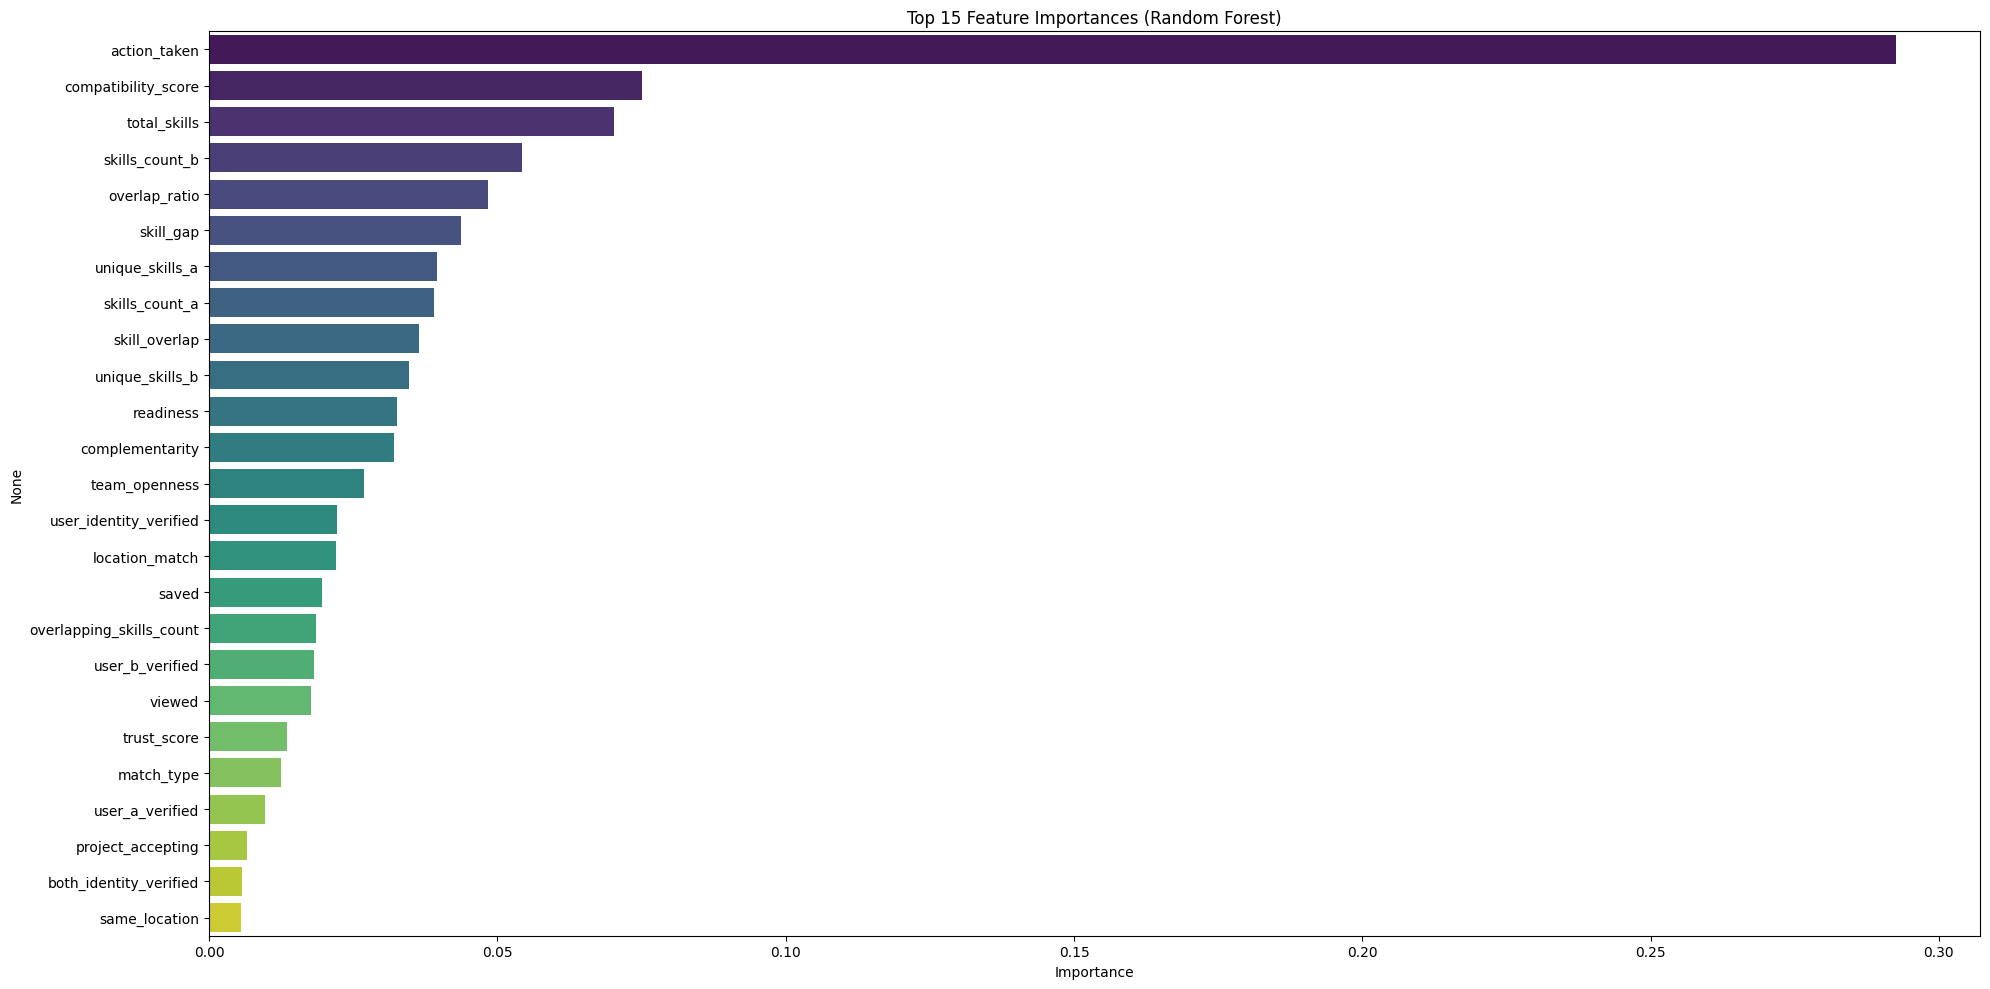

In [24]:
# Feature importance plot
feat_imp = pd.Series(rf.feature_importances_, index=x.columns).sort_values(ascending=False)
plt.figure(figsize=(20, 10))
sns.barplot(x=feat_imp.values[:25], y=feat_imp.index[:25], palette='viridis')
plt.title('Top 15 Feature Importances (Random Forest)')
plt.xlabel('Importance')
plt.tight_layout()
plt.show()


# Predictions & Evaluation

In [25]:
y_pred      = rf.predict(x_test_sc)
y_pred_prob = rf.predict_proba(x_test_sc)[:, 1]  # احتمال أن الـ match relevant

# Metrics
print('=' * 55)
print('Classification Report')
print('=' * 55)
print(classification_report(y_test, y_pred, target_names=['Not Relevant', 'Relevant']))

auc = roc_auc_score(y_test, y_pred_prob)
print(f'ROC-AUC Score: {auc:.4f}')

Classification Report
              precision    recall  f1-score   support

Not Relevant       0.87      0.86      0.86       223
    Relevant       0.18      0.20      0.19        35

    accuracy                           0.77       258
   macro avg       0.53      0.53      0.53       258
weighted avg       0.78      0.77      0.77       258

ROC-AUC Score: 0.7278


# Confusion Matrix

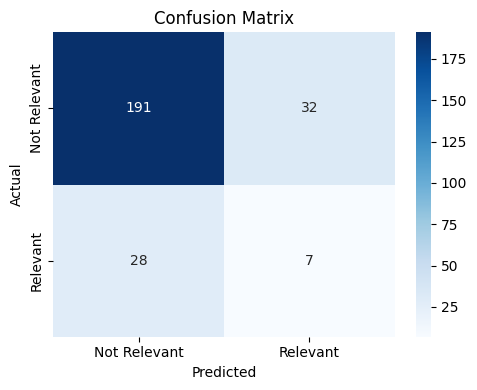

In [26]:
cm = confusion_matrix(y_test, y_pred)
plt.figure(figsize=(5, 4))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues',
            xticklabels=['Not Relevant', 'Relevant'],
            yticklabels=['Not Relevant', 'Relevant'])
plt.ylabel('Actual')
plt.xlabel('Predicted')
plt.title('Confusion Matrix')
plt.tight_layout()
plt.show()


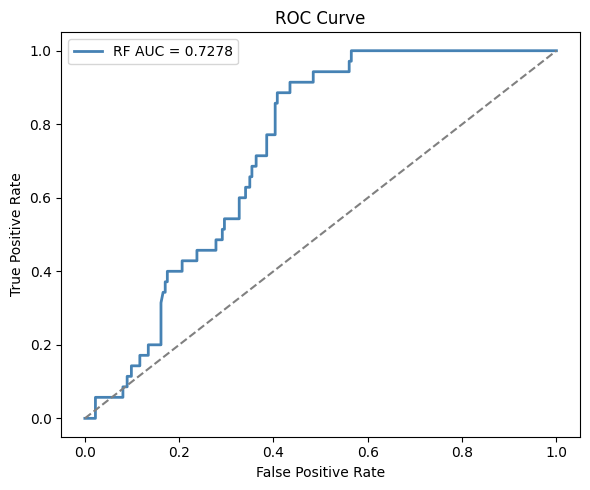

In [28]:
fpr, tpr, _ = roc_curve(y_test, y_pred_prob)
plt.figure(figsize=(6, 5))
plt.plot(fpr, tpr, label=f'RF AUC = {auc:.4f}', color='steelblue', lw=2)
plt.plot([0,1],[0,1],'--', color='gray')
plt.xlabel('False Positive Rate')
plt.ylabel('True Positive Rate')
plt.title('ROC Curve')
plt.legend()
plt.tight_layout()
plt.show()


In [31]:
#Export Results
import joblib
#Add predictions to test set and save CSV
results_df = x_test.copy()
results_df['actual_label']       = y_test.values
results_df['predicted_label']    = y_pred
results_df['predicted_prob']     = y_pred_prob.round(4)
results_df['correct_prediction'] = (results_df['actual_label'] == results_df['predicted_label']).astype(int)

results_csv = 'matches_predictions.csv'
results_df.to_csv(results_csv, index=False)
print(f'✅ Predictions saved → {results_csv}')

# Summary stats
print('\n' + '='*45)
print('FINAL SUMMARY')
print('='*45)
print(f'Total test samples :  {len(y_test)}')
print(f'Correct predictions:  {results_df["correct_prediction"].sum()}')
print(f'Accuracy           :  {results_df["correct_prediction"].mean():.2%}')
print(f'ROC-AUC            :  {auc:.4f}')
print('='*45)


✅ Predictions saved → matches_predictions.csv
✅ Model saved  → rf_model.pkl
✅ Scaler saved → scaler.pkl

FINAL SUMMARY
Total test samples :  258
Correct predictions:  198
Accuracy           :  76.74%
ROC-AUC            :  0.7278
